# Week 9: Gradient Boosting

## Research Question
Can Gradient Boosting improve NBA game-total predictions
beyond sportsbook expectations?

### Objectives
1. Apply Gradient Boosting to regression and classification.
2. Explore learning rate and number of estimators.
3. Investigate tree depth, regularization, and overfitting.
4. Tune hyperparameters using chronological cross-validation.
5. Compare models against sportsbook and classification baselines.
6. Evaluate whether historical NBA performance adds predictive value.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.ensemble import (
    GradientBoostingRegressor,
    GradientBoostingClassifier
)

from sklearn.model_selection import (
    TimeSeriesSplit,
    GridSearchCV,
    ParameterGrid,
    cross_validate
)

from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)


In [3]:
df = pd.read_csv(
    "../data/processed/merged_games_betting.csv",
    low_memory=False
)

# Create the chronological date column
df["game_date"] = pd.to_datetime(df["gameDate"])

# Sort oldest to newest
df = df.sort_values("game_date").reset_index(drop=True)

# Sportsbook prediction error
df["score_residual"] = df["actual_total"] - df["total"]

print("Dataset shape:", df.shape)
print("Earliest game:", df["game_date"].min())
print("Latest game:", df["game_date"].max())

print("\nSportsbook error distribution:")
print(df["score_residual"].describe().round(2))

display(df[[
    "game_date",
    "hometeamId",
    "awayteamId",
    "total",
    "actual_total",
    "score_residual"
]].head())

Dataset shape: (21965, 56)
Earliest game: 2007-10-30 00:00:00
Latest game: 2025-06-19 00:00:00

Sportsbook error distribution:
count    21965.00
mean         0.37
std         17.77
min        -66.00
25%        -11.50
50%          0.00
75%         11.50
max        112.50
Name: score_residual, dtype: float64


,game_date,hometeamId,awayteamId,total,actual_total,score_residual
0,2007-10-30,1610612759,1610612757,189.5,203,13.5
1,2007-10-30,1610612744,1610612762,212.0,213,1.0
2,2007-10-30,1610612747,1610612745,199.0,188,-11.0
3,2007-10-31,1610612754,1610612764,203.5,229,25.5
4,2007-10-31,1610612753,1610612749,197.0,185,-12.0


In [4]:
# Identify chronological cutoff
split_idx = int(len(df) * 0.80)
cutoff_date = df.loc[split_idx, "game_date"]

# Keep same-day games together
train_df = df[df["game_date"] < cutoff_date].copy()
test_df = df[df["game_date"] >= cutoff_date].copy()

# Sportsbook baseline
sportsbook_mae = mean_absolute_error(
    test_df["actual_total"],
    test_df["total"]
)

sportsbook_rmse = np.sqrt(
    mean_squared_error(
        test_df["actual_total"],
        test_df["total"]
    )
)

print("Training games:", len(train_df))
print("Testing games:", len(test_df))

print("\nTraining period:",
      train_df["game_date"].min(),
      "to",
      train_df["game_date"].max())

print("\nTesting period:",
      test_df["game_date"].min(),
      "to",
      test_df["game_date"].max())

print("\nSportsbook Benchmark")
print(f"MAE: {sportsbook_mae:.4f}")
print(f"RMSE: {sportsbook_rmse:.4f}")

Training games: 17568
Testing games: 4397

Training period: 2007-10-30 00:00:00 to 2022-02-16 00:00:00

Testing period: 2022-02-17 00:00:00 to 2025-06-19 00:00:00

Sportsbook Benchmark
MAE: 14.1386
RMSE: 17.8186


## Feature Engineering: Historical Team Performance

Historical NBA performance features are created to provide
additional predictive information beyond sportsbook betting lines.

Features include:
- Rolling averages of points scored and allowed (5 and 10 games)
- Historical scoring residuals relative to sportsbook totals
- Estimated combined scoring based on recent team performance
- Team rest days

Rolling statistics are shifted by one game to ensure that
current game results are never included in their own predictors.

These features will be evaluated using chronological
cross-validation to assess their usefulness.

In [5]:
games = df.copy()

home_col = "hometeamId"
away_col = "awayteamId"

# Create one observation per team per game
home_games = pd.DataFrame({
    "team": games[home_col].astype(str),
    "game_date": games["game_date"],
    "points_for": games["homeScore"],
    "points_against": games["awayScore"],
    "residual": games["score_residual"]
})

away_games = pd.DataFrame({
    "team": games[away_col].astype(str),
    "game_date": games["game_date"],
    "points_for": games["awayScore"],
    "points_against": games["homeScore"],
    "residual": games["score_residual"]
})

team_games = pd.concat(
    [home_games, away_games],
    ignore_index=True
)

# Aggregate by team and date to avoid same-day leakage
daily = (
    team_games
    .groupby(["team", "game_date"], as_index=False)
    .agg({
        "points_for": "mean",
        "points_against": "mean",
        "residual": "mean"
    })
    .sort_values(["team", "game_date"])
    .reset_index(drop=True)
)

# Create lagged rolling averages
for window in [5, 10]:
    for col in ["points_for", "points_against", "residual"]:

        daily[f"{col}_{window}"] = (
            daily.groupby("team")[col]
            .transform(
                lambda s: s.shift(1)
                .rolling(window, min_periods=3)
                .mean()
            )
        )

# Calculate days of rest before each game
previous_date = daily.groupby("team")["game_date"].shift(1)

daily["rest_days"] = (
    (daily["game_date"] - previous_date).dt.days - 1
).clip(lower=0, upper=7)

# Historical team features
history_cols = [
    "points_for_5",
    "points_against_5",
    "residual_5",
    "points_for_10",
    "points_against_10",
    "residual_10",
    "rest_days"
]

# Home team history
home_history = daily[
    ["team", "game_date"] + history_cols
].rename(columns={
    "team": home_col,
    **{col: f"home_{col}" for col in history_cols}
})

# Away team history
away_history = daily[
    ["team", "game_date"] + history_cols
].rename(columns={
    "team": away_col,
    **{col: f"away_{col}" for col in history_cols}
})

# Match team ID types
games[home_col] = games[home_col].astype(str)
games[away_col] = games[away_col].astype(str)

# Merge historical statistics into NBA games
games = games.merge(
    home_history,
    on=[home_col, "game_date"],
    how="left",
    validate="many_to_one"
)

games = games.merge(
    away_history,
    on=[away_col, "game_date"],
    how="left",
    validate="many_to_one"
)

# Estimate combined scoring from recent team history
for window in [5, 10]:

    games[f"expected_total_{window}"] = (
        games[f"home_points_for_{window}"]
        + games[f"away_points_against_{window}"]
        + games[f"away_points_for_{window}"]
        + games[f"home_points_against_{window}"]
    ) / 2

    games[f"scoring_edge_{window}"] = (
        games[f"expected_total_{window}"] - games["total"]
    )

# Additional pregame features
games["recent_residual_5"] = (
    games["home_residual_5"]
    + games["away_residual_5"]
) / 2

games["rest_difference"] = (
    games["home_rest_days"]
    - games["away_rest_days"]
)

# Select modeling features
gb_features = [
    "total",
    "spread",
    "expected_total_5",
    "expected_total_10",
    "scoring_edge_5",
    "scoring_edge_10",
    "recent_residual_5",
    "rest_difference",
    "home_points_for_5",
    "away_points_for_5",
    "home_points_against_5",
    "away_points_against_5"
]

print("Dataset shape after feature engineering:", games.shape)

print("\nGradient Boosting features:")
print(gb_features)

print("\nMissing values:")
display(games[gb_features].isna().sum())

print("\nSample observations:")
display(
    games[
        ["game_date", "total", "actual_total"]
        + gb_features[2:8]
    ].tail()
)

Dataset shape after feature engineering: (21965, 76)

Gradient Boosting features:
['total', 'spread', 'expected_total_5', 'expected_total_10', 'scoring_edge_5', 'scoring_edge_10', 'recent_residual_5', 'rest_difference', 'home_points_for_5', 'away_points_for_5', 'home_points_against_5', 'away_points_against_5']

Missing values:


total                     0
spread                    3
expected_total_5         54
expected_total_10        54
scoring_edge_5           54
scoring_edge_10          54
recent_residual_5        54
rest_difference          20
home_points_for_5        46
away_points_for_5        44
home_points_against_5    46
away_points_against_5    44
dtype: int64


Sample observations:


,game_date,total,actual_total,expected_total_5,expected_total_10,scoring_edge_5,scoring_edge_10,recent_residual_5,rest_difference
21960,2025-06-08,227.5,230,227.4,224.95,-0.1,-2.55,5.2,0.0
21961,2025-06-11,225.5,223,230.7,227.50,5.2,2.00,7.2,0.0
21962,2025-06-13,227.5,215,225.8,227.05,-1.7,-0.45,0.7,0.0
21963,2025-06-16,223.5,229,222.9,226.30,-0.6,2.80,-3.5,0.0
21964,2025-06-19,222.5,199,223.6,224.65,1.1,2.15,-3.1,0.0


## Initial Gradient Boosting Regression

A Gradient Boosting Regressor is trained to predict the difference
between actual NBA game scores and sportsbook totals.

The model uses historical team performance and betting information
to estimate corrections to sportsbook expectations.

Initial hyperparameters:
- Learning rate: 0.05
- Number of estimators: 100
- Maximum tree depth: 2
- Subsample: 0.8
- Minimum samples per leaf: 20

Chronological cross-validation is used to compare model
performance against the sportsbook benchmark while avoiding
hyperparameter selection on the final test set.

In [6]:
# Preserve the original chronological split
gb_train = games[games["game_date"] < cutoff_date].copy()
gb_test = games[games["game_date"] >= cutoff_date].copy()

# Predictors
X_train_gb = gb_train[gb_features]
X_test_gb = gb_test[gb_features]

# Target: actual total minus sportsbook prediction
y_train_gb = gb_train["score_residual"]
y_test_gb = gb_test["score_residual"]

# Keep same-day NBA games together in chronological CV
unique_dates = np.sort(gb_train["game_date"].unique())

tscv = TimeSeriesSplit(n_splits=4)
gb_cv_splits = []

for train_dates_idx, val_dates_idx in tscv.split(unique_dates):

    train_dates = unique_dates[train_dates_idx]
    val_dates = unique_dates[val_dates_idx]

    train_idx = np.flatnonzero(
        gb_train["game_date"].isin(train_dates).to_numpy()
    )

    val_idx = np.flatnonzero(
        gb_train["game_date"].isin(val_dates).to_numpy()
    )

    gb_cv_splits.append((train_idx, val_idx))

# Initial Gradient Boosting pipeline
gb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=2,
        subsample=0.8,
        min_samples_leaf=20,
        random_state=42
    ))
])

# Evaluate across chronological folds
gb_cv_scores = cross_validate(
    gb_pipeline,
    X_train_gb,
    y_train_gb,
    cv=gb_cv_splits,
    scoring="neg_mean_absolute_error",
    return_train_score=True
)

# Sportsbook baseline on identical validation folds
sportsbook_cv_mae = np.mean([
    np.abs(y_train_gb.iloc[val_idx]).mean()
    for _, val_idx in gb_cv_splits
])

# Results
initial_gb_results = pd.DataFrame({
    "Model": [
        "Sportsbook Benchmark",
        "Initial Gradient Boosting"
    ],
    "CV MAE": [
        sportsbook_cv_mae,
        -gb_cv_scores["test_score"].mean()
    ]
})

print(
    "Gradient Boosting Training MAE:",
    round(-gb_cv_scores["train_score"].mean(), 4)
)

print(
    "Gradient Boosting Validation MAE:",
    round(-gb_cv_scores["test_score"].mean(), 4)
)

display(initial_gb_results.round(4))

Gradient Boosting Training MAE: 13.6564
Gradient Boosting Validation MAE: 14.0215


,Model,CV MAE
0,Sportsbook Benchmark,13.9585
1,Initial Gradient Boosting,14.0215


## Learning Rate and Number of Estimators

This experiment examines how the learning rate and number of
boosting iterations influence NBA game-total prediction accuracy.

Three learning rates (0.01, 0.05, and 0.10) and three numbers of
estimators (50, 100, and 200) are evaluated.

Tree depth and other regularization parameters are held constant
to isolate the effects of these two hyperparameters.

Chronological cross-validation minimizes MAE when selecting
the best configuration. Training and validation errors are
compared to investigate overfitting.

In [7]:
# Pipeline with fixed tree depth and regularization
gb_tuning_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", GradientBoostingRegressor(
        max_depth=2,
        subsample=0.8,
        min_samples_leaf=20,
        random_state=42
    ))
])

# Tune two main Gradient Boosting parameters
gb_param_grid = {
    "model__learning_rate": [0.01, 0.05, 0.10],
    "model__n_estimators": [50, 100, 200]
}

gb_grid = GridSearchCV(
    estimator=gb_tuning_pipeline,
    param_grid=gb_param_grid,
    cv=gb_cv_splits,
    scoring="neg_mean_absolute_error",
    n_jobs=2,
    return_train_score=True
)

# Fit using training data only
gb_grid.fit(X_train_gb, y_train_gb)

# Examine all combinations
gb_tuning_results = pd.DataFrame({
    "Learning Rate": gb_grid.cv_results_["param_model__learning_rate"],
    "Estimators": gb_grid.cv_results_["param_model__n_estimators"],
    "Training MAE": -gb_grid.cv_results_["mean_train_score"],
    "CV MAE": -gb_grid.cv_results_["mean_test_score"]
})

gb_tuning_results = gb_tuning_results.sort_values("CV MAE")

print("Best parameters:")
print(gb_grid.best_params_)

print("\nBest Gradient Boosting CV MAE:")
print(round(-gb_grid.best_score_, 4))

print("\nSportsbook CV MAE:")
print(round(sportsbook_cv_mae, 4))

print("\nHyperparameter comparison:")
display(gb_tuning_results.round(4))

Best parameters:
{'model__learning_rate': 0.01, 'model__n_estimators': 50}

Best Gradient Boosting CV MAE:
13.9619

Sportsbook CV MAE:
13.9585

Hyperparameter comparison:


,Learning Rate,Estimators,Training MAE,CV MAE
0,0.01,50,13.7858,13.9619
1,0.01,100,13.7670,13.9668
2,0.01,200,13.7338,13.9802
3,0.05,50,13.7218,13.9894
4,0.05,100,13.6564,14.0215
6,0.10,50,13.6575,14.0253
5,0.05,200,13.5390,14.0501
7,0.10,100,13.5442,14.0744
8,0.10,200,13.3526,14.1316


## Tree Depth and Regularization

This experiment examines the effects of tree complexity and
regularization on Gradient Boosting regression performance.

The learning rate and number of estimators are fixed at
the best values from the previous experiment.

Three hyperparameters are evaluated:
- Maximum tree depth (max_depth)
- Minimum samples per leaf (min_samples_leaf)
- Training subsample proportion (subsample)

Chronological cross-validation is used to select the best
configuration based on MAE.

Training and validation errors are compared to identify
potential overfitting.

In [8]:
regularization_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", GradientBoostingRegressor(
        learning_rate=0.01,
        n_estimators=50,
        random_state=42
    ))
])

regularization_grid = {
    "model__max_depth": [1, 2, 3],
    "model__min_samples_leaf": [20, 50, 100],
    "model__subsample": [0.6, 0.8]
}

gb_reg_grid = GridSearchCV(
    estimator=regularization_pipeline,
    param_grid=regularization_grid,
    cv=gb_cv_splits,
    scoring="neg_mean_absolute_error",
    n_jobs=2,
    return_train_score=True
)

gb_reg_grid.fit(X_train_gb, y_train_gb)

# Extract results
gb_reg_results = pd.DataFrame({
    "Tree Depth":
        gb_reg_grid.cv_results_["param_model__max_depth"],
    "Min Samples Leaf":
        gb_reg_grid.cv_results_["param_model__min_samples_leaf"],
    "Subsample":
        gb_reg_grid.cv_results_["param_model__subsample"],
    "Training MAE":
        -gb_reg_grid.cv_results_["mean_train_score"],
    "CV MAE":
        -gb_reg_grid.cv_results_["mean_test_score"]
})

gb_reg_results["Overfitting Gap"] = (
    gb_reg_results["CV MAE"]
    - gb_reg_results["Training MAE"]
)

gb_reg_results = gb_reg_results.sort_values("CV MAE")

print("Best regularization parameters:")
print(gb_reg_grid.best_params_)

print("\nBest regularized Gradient Boosting CV MAE:")
print(round(-gb_reg_grid.best_score_, 4))

print("\nPrevious best CV MAE:")
print(round(-gb_grid.best_score_, 4))

print("\nSportsbook CV MAE:")
print(round(sportsbook_cv_mae, 4))

print("\nTop 10 configurations:")
display(gb_reg_results.head(10).round(4))

Best regularization parameters:
{'model__max_depth': 2, 'model__min_samples_leaf': 50, 'model__subsample': 0.6}

Best regularized Gradient Boosting CV MAE:
13.9598

Previous best CV MAE:
13.9619

Sportsbook CV MAE:
13.9585

Top 10 configurations:


,Tree Depth,Min Samples Leaf,Subsample,Training MAE,CV MAE,Overfitting Gap
8,2,50,0.6,13.7869,13.9598,0.1729
2,1,50,0.6,13.8002,13.9604,0.1602
12,3,20,0.6,13.7658,13.9604,0.1946
6,2,20,0.6,13.7850,13.9604,0.1754
4,1,100,0.6,13.8007,13.9606,0.1599
0,1,20,0.6,13.7998,13.9606,0.1608
5,1,100,0.8,13.8006,13.9607,0.1601
10,2,100,0.6,13.7877,13.9609,0.1732
3,1,50,0.8,13.8004,13.9611,0.1606
14,3,50,0.6,13.7691,13.9614,0.1923


## Gradient Boosting: Learning Rate and Estimator Comparison

This figure examines how learning rate and number of boosting
estimators affect cross-validation MAE.

The sportsbook benchmark is included as a reference.

The goal is to identify whether increasing model complexity
improves generalization or increases overfitting.

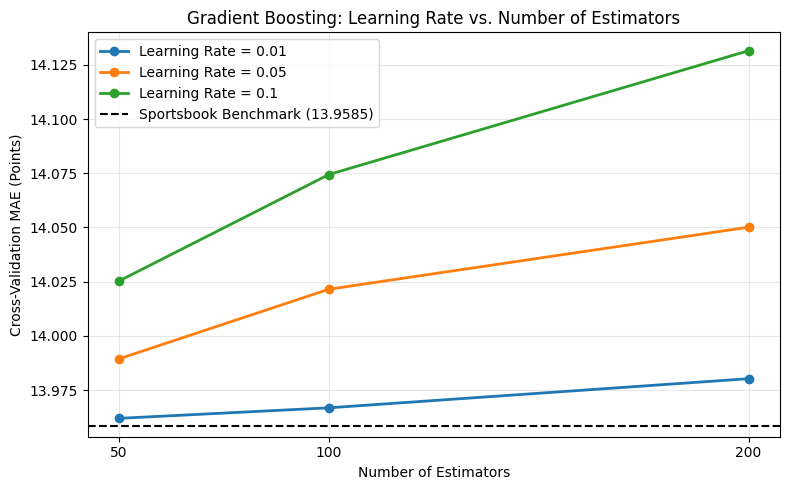

In [9]:

# Prepare results from the earlier GridSearchCV
plot_df = gb_tuning_results.copy()

plot_df["Learning Rate"] = pd.to_numeric(
    plot_df["Learning Rate"]
)

plot_df["Estimators"] = pd.to_numeric(
    plot_df["Estimators"]
)

fig, ax = plt.subplots(figsize=(8, 5))

# Plot validation MAE for each learning rate
for lr in sorted(plot_df["Learning Rate"].unique()):

    subset = (
        plot_df[plot_df["Learning Rate"] == lr]
        .sort_values("Estimators")
    )

    ax.plot(
        subset["Estimators"],
        subset["CV MAE"],
        marker="o",
        linewidth=2,
        label=f"Learning Rate = {lr}"
    )

# Add sportsbook benchmark
ax.axhline(
    sportsbook_cv_mae,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label=f"Sportsbook Benchmark ({sportsbook_cv_mae:.4f})"
)

ax.set_title(
    "Gradient Boosting: Learning Rate vs. Number of Estimators"
)

ax.set_xlabel("Number of Estimators")
ax.set_ylabel("Cross-Validation MAE (Points)")

ax.set_xticks([50, 100, 200])
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()

# Save figure
Path("../figures").mkdir(parents=True, exist_ok=True)

plt.savefig(
    "../figures/week09_learning_rate_estimators.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Gradient Boosting Classification

Gradient Boosting Classification is used to predict whether an
NBA game finishes Over or Under the sportsbook total.

Games finishing exactly on the betting line are excluded.

Historical team performance and sportsbook information are
used as predictors.

Chronological cross-validation is used to evaluate the model,
while ROC AUC measures its ability to distinguish Over from
Under outcomes.

In [10]:
# Remove pushes
gb_class = games[
    games["actual_total"] != games["total"]
].copy()

# Create classification target
gb_class["over"] = (
    gb_class["actual_total"] > gb_class["total"]
).astype(int)

# Preserve chronological train/test boundary
gb_class_train = gb_class[
    gb_class["game_date"] < cutoff_date
].copy()

gb_class_test = gb_class[
    gb_class["game_date"] >= cutoff_date
].copy()

# Use our historical features
X_train_cls = gb_class_train[gb_features]
X_test_cls = gb_class_test[gb_features]

y_train_cls = gb_class_train["over"]
y_test_cls = gb_class_test["over"]

# Chronological cross-validation, keeping dates together
unique_class_dates = np.sort(
    gb_class_train["game_date"].unique()
)

class_cv_splits = []

for tr_dates, val_dates in TimeSeriesSplit(
    n_splits=4
).split(unique_class_dates):

    train_dates = unique_class_dates[tr_dates]
    val_dates = unique_class_dates[val_dates]

    tr_idx = np.flatnonzero(
        gb_class_train["game_date"].isin(train_dates).to_numpy()
    )

    val_idx = np.flatnonzero(
        gb_class_train["game_date"].isin(val_dates).to_numpy()
    )

    class_cv_splits.append((tr_idx, val_idx))

# Initial Gradient Boosting Classifier
gb_class_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", GradientBoostingClassifier(
        learning_rate=0.05,
        n_estimators=100,
        max_depth=2,
        min_samples_leaf=50,
        subsample=0.8,
        random_state=42
    ))
])

# Cross-validation performance
gb_class_scores = cross_validate(
    gb_class_pipeline,
    X_train_cls,
    y_train_cls,
    cv=class_cv_splits,
    scoring="roc_auc",
    return_train_score=True,
    n_jobs=2
)

print("Training games:", len(gb_class_train))
print("Testing games:", len(gb_class_test))

print("\nTraining ROC AUC:",
      round(gb_class_scores["train_score"].mean(), 4))

print("Cross-Validation ROC AUC:",
      round(gb_class_scores["test_score"].mean(), 4))

print("\nIndividual validation folds:")
print(np.round(gb_class_scores["test_score"], 4))

Training games: 17331
Testing games: 4381

Training ROC AUC: 0.6124
Cross-Validation ROC AUC: 0.5068

Individual validation folds:
[0.5103 0.5075 0.5025 0.5071]


## Gradient Boosting Classification Hyperparameter Tuning

This experiment investigates whether regularization can reduce
overfitting and improve Over/Under classification.

Learning rate, number of estimators, maximum tree depth,
and minimum samples per leaf are tuned using chronological
cross-validation.

ROC AUC is used for model selection. Training and validation
scores are compared to assess generalization.

In [11]:
gb_class_tuning_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", GradientBoostingClassifier(
        subsample=0.6,
        random_state=42
    ))
])

class_param_grid = {
    "model__learning_rate": [0.01, 0.05],
    "model__n_estimators": [50, 100, 200],
    "model__max_depth": [1, 2],
    "model__min_samples_leaf": [50, 100]
}

gb_class_grid = GridSearchCV(
    estimator=gb_class_tuning_pipeline,
    param_grid=class_param_grid,
    cv=class_cv_splits,
    scoring="roc_auc",
    n_jobs=2,
    return_train_score=True
)

gb_class_grid.fit(X_train_cls, y_train_cls)

# Extract tuning results
class_tuning_results = pd.DataFrame({
    "Learning Rate":
        gb_class_grid.cv_results_["param_model__learning_rate"],
    "Estimators":
        gb_class_grid.cv_results_["param_model__n_estimators"],
    "Tree Depth":
        gb_class_grid.cv_results_["param_model__max_depth"],
    "Min Samples Leaf":
        gb_class_grid.cv_results_["param_model__min_samples_leaf"],
    "Training AUC":
        gb_class_grid.cv_results_["mean_train_score"],
    "CV AUC":
        gb_class_grid.cv_results_["mean_test_score"]
})

# Calculate overfitting gap
class_tuning_results["Overfitting Gap"] = (
    class_tuning_results["Training AUC"]
    - class_tuning_results["CV AUC"]
)

# Sort by validation performance
class_tuning_results = class_tuning_results.sort_values(
    "CV AUC",
    ascending=False
)

print("Best parameters:")
print(gb_class_grid.best_params_)

print("\nBest CV ROC AUC:")
print(round(gb_class_grid.best_score_, 4))

print("\nInitial CV ROC AUC:")
print(round(gb_class_scores["test_score"].mean(), 4))

print("\nTop 10 configurations:")
display(class_tuning_results.head(10).round(4))

Best parameters:
{'model__learning_rate': 0.05, 'model__max_depth': 2, 'model__min_samples_leaf': 100, 'model__n_estimators': 200}

Best CV ROC AUC:
0.5089

Initial CV ROC AUC:
0.5068

Top 10 configurations:


,Learning Rate,Estimators,Tree Depth,Min Samples Leaf,Training AUC,CV AUC,Overfitting Gap
23,0.05,200,2,100,0.6323,0.5089,0.1234
21,0.05,50,2,100,0.5838,0.5079,0.0759
22,0.05,100,2,100,0.6053,0.5069,0.0983
12,0.05,50,1,50,0.5509,0.5063,0.0446
20,0.05,200,2,50,0.6399,0.5059,0.1339
9,0.01,50,2,100,0.5651,0.5057,0.0594
14,0.05,200,1,50,0.5777,0.5056,0.0721
13,0.05,100,1,50,0.5633,0.5055,0.0578
6,0.01,50,2,50,0.5683,0.5054,0.0629
17,0.05,200,1,100,0.5734,0.5051,0.0683


## Final Gradient Boosting Regression Evaluation

The best regularized Gradient Boosting Regressor is evaluated
on the held-out 2022–2025 NBA games.

The model predicts corrections to sportsbook totals.

Final predictions are compared against the sportsbook benchmark
using MAE and RMSE. Training error is also examined to assess
generalization.

In [12]:
# Best regression model from chronological cross-validation
best_gb_reg = gb_reg_grid.best_estimator_

# Predict sportsbook residuals
train_residual_pred = best_gb_reg.predict(X_train_gb)
test_residual_pred = best_gb_reg.predict(X_test_gb)

# Convert residual predictions into predicted NBA game totals
train_total_pred = (
    gb_train["total"].to_numpy() + train_residual_pred
)

test_total_pred = (
    gb_test["total"].to_numpy() + test_residual_pred
)

# Evaluate predictions
gb_train_mae = mean_absolute_error(
    gb_train["actual_total"], train_total_pred
)

gb_test_mae = mean_absolute_error(
    gb_test["actual_total"], test_total_pred
)

gb_test_rmse = np.sqrt(
    mean_squared_error(gb_test["actual_total"], test_total_pred)
)

# Compare to sportsbook benchmark
regression_results = pd.DataFrame({
    "Model": [
        "Sportsbook Benchmark",
        "Optimized Gradient Boosting"
    ],
    "Test MAE": [
        sportsbook_mae,
        gb_test_mae
    ],
    "Test RMSE": [
        sportsbook_rmse,
        gb_test_rmse
    ]
})

print("GB Training MAE:", round(gb_train_mae, 4))
print("GB Testing MAE:", round(gb_test_mae, 4))
print("Train-Test MAE Gap:", round(gb_test_mae - gb_train_mae, 4))

display(regression_results.round(4))

GB Training MAE: 13.9485
GB Testing MAE: 14.1346
Train-Test MAE Gap: 0.1861


,Model,Test MAE,Test RMSE
0,Sportsbook Benchmark,14.1386,17.8186
1,Optimized Gradient Boosting,14.1346,17.8134


## Final Gradient Boosting Classification Evaluation

The optimized Gradient Boosting classifier is evaluated on
held-out NBA games from February 2022 through June 2025.

Performance is measured using accuracy, precision, recall,
F1 score, and ROC AUC.

Training and testing ROC AUC are also compared to assess
whether the model generalizes to unseen games.

In [13]:
# Best model from chronological cross-validation
best_gb_class = gb_class_grid.best_estimator_

# Generate predictions
gb_class_train_pred = best_gb_class.predict(X_train_cls)
gb_class_test_pred = best_gb_class.predict(X_test_cls)

# Predicted probability of Over (class 1)
gb_class_train_proba = best_gb_class.predict_proba(X_train_cls)[:, 1]
gb_class_test_proba = best_gb_class.predict_proba(X_test_cls)[:, 1]

# Training and testing ROC AUC
gb_train_auc = roc_auc_score(
    y_train_cls, gb_class_train_proba
)

gb_test_auc = roc_auc_score(
    y_test_cls, gb_class_test_proba
)

print("Training ROC AUC:", round(gb_train_auc, 4))
print("Testing ROC AUC:", round(gb_test_auc, 4))
print("Train-Test AUC Gap:", round(gb_train_auc - gb_test_auc, 4))

# Majority baseline based on training observations
majority_class = int(y_train_cls.mode().iloc[0])

baseline_pred = np.full(
    len(y_test_cls),
    majority_class
)

# Compare classification performance
classification_results = pd.DataFrame({
    "Model": [
        "Majority Baseline",
        "Optimized Gradient Boosting"
    ],
    "Accuracy": [
        accuracy_score(y_test_cls, baseline_pred),
        accuracy_score(y_test_cls, gb_class_test_pred)
    ],
    "Precision": [
        precision_score(y_test_cls, baseline_pred, zero_division=0),
        precision_score(y_test_cls, gb_class_test_pred, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test_cls, baseline_pred, zero_division=0),
        recall_score(y_test_cls, gb_class_test_pred, zero_division=0)
    ],
    "F1": [
        f1_score(y_test_cls, baseline_pred, zero_division=0),
        f1_score(y_test_cls, gb_class_test_pred, zero_division=0)
    ],
    "ROC AUC": [
        0.5,
        gb_test_auc
    ]
})

display(classification_results.round(4))

Training ROC AUC: 0.5921
Testing ROC AUC: 0.5073
Train-Test AUC Gap: 0.0848


,Model,Accuracy,Precision,Recall,F1,ROC AUC
0,Majority Baseline,0.4919,0.0000,0.0000,0.0000,0.5000
1,Optimized Gradient Boosting,0.5047,0.5167,0.3899,0.4444,0.5073


## Gradient Boosting Classification: Overfitting Analysis

This visualization examines how increasing the number of
boosting estimators affects training and cross-validation ROC AUC.

Learning rate, tree depth, minimum leaf size, and subsample
are held constant to isolate the effect of estimator count.

The objective is to determine whether additional trees
improve generalization or primarily increase overfitting.

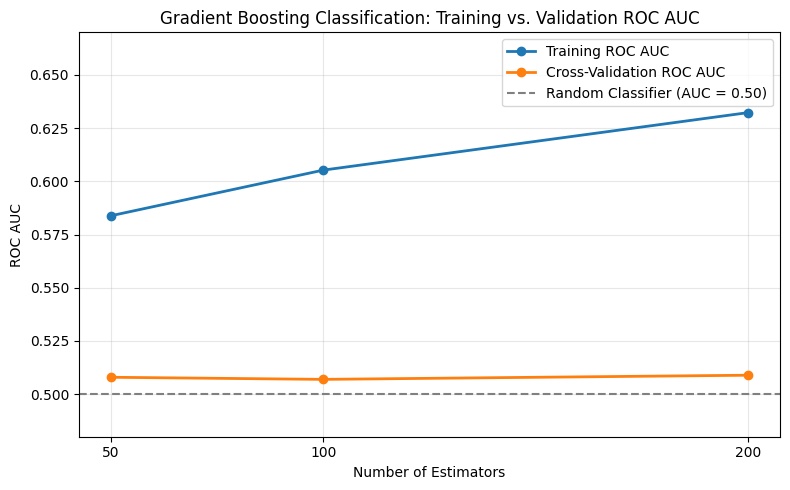

,Estimators,Training AUC,CV AUC,Overfitting Gap
21,50,0.5838,0.5079,0.0759
22,100,0.6053,0.5069,0.0983
23,200,0.6323,0.5089,0.1234


In [14]:
# Extract cross-validation results
plot_df = class_tuning_results.copy()

# Ensure numerical types
for col in [
    "Learning Rate",
    "Estimators",
    "Tree Depth",
    "Min Samples Leaf"
]:
    plot_df[col] = pd.to_numeric(plot_df[col])

# Hold parameters constant and compare estimator counts
subset = plot_df[
    (plot_df["Learning Rate"] == 0.05) &
    (plot_df["Tree Depth"] == 2) &
    (plot_df["Min Samples Leaf"] == 100)
].sort_values("Estimators")

# Plot training vs cross-validation ROC AUC
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    subset["Estimators"],
    subset["Training AUC"],
    marker="o",
    linewidth=2,
    label="Training ROC AUC"
)

ax.plot(
    subset["Estimators"],
    subset["CV AUC"],
    marker="o",
    linewidth=2,
    label="Cross-Validation ROC AUC"
)

# Random-classification reference
ax.axhline(
    y=0.5,
    linestyle="--",
    color="gray",
    label="Random Classifier (AUC = 0.50)"
)

ax.set_title(
    "Gradient Boosting Classification: Training vs. Validation ROC AUC"
)
ax.set_xlabel("Number of Estimators")
ax.set_ylabel("ROC AUC")
ax.set_xticks([50, 100, 200])
ax.set_ylim(0.48, 0.67)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()

# Save for Milestone Two
Path("../figures").mkdir(parents=True, exist_ok=True)

plt.savefig(
    "../figures/week09_classification_overfitting.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Display supporting results
display(
    subset[
        ["Estimators", "Training AUC", "CV AUC", "Overfitting Gap"]
    ].round(4)
)

## Week 9 Conclusions and Key Findings

### Regression Results

Gradient Boosting Regression was used to predict corrections to
sportsbook totals based on historical NBA performance.

Chronological cross-validation showed that smaller learning
rates and fewer estimators generally produced better results.
Increasing the number of trees lowered training error but
increased validation error, suggesting overfitting.

The best regularized model used:
- Learning rate: 0.01
- Estimators: 50
- Maximum depth: 2
- Minimum samples per leaf: 50
- Subsample: 0.6

The optimized model achieved a test MAE of 14.1346, compared
with 14.1386 for the sportsbook benchmark.

Although Gradient Boosting slightly outperformed the sportsbook,
the improvement of 0.004 points was practically negligible.

### Classification Results

Gradient Boosting Classification was applied to predict
NBA Over/Under outcomes using sportsbook and historical
team-performance features.

The optimized classifier achieved:
- Test accuracy: 50.47%
- Test ROC AUC: 0.5073
- Training ROC AUC: 0.5921

The large difference between training and testing ROC AUC
indicates that the classifier struggled to generalize.

Increasing the number of estimators improved training
performance but provided almost no improvement in
cross-validation ROC AUC.

### Expected and Unexpected Findings

As expected, increasing the number of estimators allowed
Gradient Boosting to fit the training data more closely.

However, it was unexpected that historical scoring trends,
defensive performance, and rest days provided so little
additional predictive value beyond sportsbook expectations.

Regression performed considerably better relative to its
benchmark than classification, suggesting that predicting
combined points is more achievable than predicting which
side of a sportsbook line a game will finish on.

### Overall Conclusion

Gradient Boosting provided a slight improvement over sportsbook
totals in the held-out regression evaluation but showed
limited ability to predict Over/Under outcomes.

The experiments demonstrate that increasing model complexity
does not guarantee better generalization. Learning rate,
tree depth, estimator count, and regularization must be
carefully evaluated using chronological cross-validation.

Because the test period has also been examined in earlier
capstone experiments, these results should be interpreted
as exploratory rather than definitive evidence of superiority.

## Additional Analysis: Uncertainty in Gradient Boosting Improvement

Gradient Boosting achieved a slightly lower test MAE than
the sportsbook benchmark.

Because the improvement was extremely small, a paired bootstrap
analysis is conducted to estimate the uncertainty surrounding
the difference in MAE.

Calendar weeks are resampled to preserve groups of games
played during the same period.

A positive MAE difference indicates that Gradient Boosting
outperformed the sportsbook.

The analysis is exploratory because the test period has
already been examined during prior model development.

In [15]:
# Paired bootstrap: Sportsbook vs. Gradient Boosting

rng = np.random.default_rng(42)

# Use the existing final regression predictions
bootstrap_df = gb_test[
    ["game_date", "actual_total", "total"]
].copy()

bootstrap_df["GB_Prediction"] = test_total_pred

# Absolute errors for both models
bootstrap_df["Sportsbook_Error"] = abs(
    bootstrap_df["actual_total"] - bootstrap_df["total"]
)

bootstrap_df["GB_Error"] = abs(
    bootstrap_df["actual_total"] - bootstrap_df["GB_Prediction"]
)

# Positive = Gradient Boosting improves on sportsbook
bootstrap_df["MAE_Improvement"] = (
    bootstrap_df["Sportsbook_Error"]
    - bootstrap_df["GB_Error"]
)

# Group games into calendar weeks
bootstrap_df["Week"] = (
    bootstrap_df["game_date"]
    .dt.to_period("W")
    .astype(str)
)

weekly = (
    bootstrap_df.groupby("Week")
    .agg(
        Error_Difference_Sum=("MAE_Improvement", "sum"),
        Games=("MAE_Improvement", "size")
    )
)

# Observed improvement
observed_improvement = bootstrap_df["MAE_Improvement"].mean()

# Bootstrap by sampling calendar weeks
n_bootstrap = 5000

sample_indices = rng.integers(
    0,
    len(weekly),
    size=(n_bootstrap, len(weekly))
)

weekly_sums = weekly["Error_Difference_Sum"].to_numpy()
weekly_counts = weekly["Games"].to_numpy()

bootstrap_improvements = (
    weekly_sums[sample_indices].sum(axis=1)
    / weekly_counts[sample_indices].sum(axis=1)
)

# 95% bootstrap confidence interval
ci_lower, ci_upper = np.percentile(
    bootstrap_improvements,
    [2.5, 97.5]
)

print("Observed MAE Improvement:",
      round(observed_improvement, 4))

print("95% Bootstrap CI:",
      (round(ci_lower, 4), round(ci_upper, 4)))

print("CI Includes Zero:",
      ci_lower <= 0 <= ci_upper)

Observed MAE Improvement: 0.004
95% Bootstrap CI: (np.float64(-0.0027), np.float64(0.0105))
CI Includes Zero: True
